# 🔗 Live Cloud Deployment Link
**Live demo:** `PASTE_YOUR_HEART_DISEASE_STREAMLIT_LINK_HERE`

---
**Course:** Machine Learning Fundamentals (AIC354) — COMSATS University Islamabad, Lahore Campus  
**Assignment 2, Task 2:** Heart Disease Prediction System  
**Student:** Mishal Fatima | **Reg. No:** SP24-BCS-067 | **Section:** B  
**Instructor:** Dr. Rao Muhammad Adeel Nawab

# Heart Disease Prediction System

## Introduction
**Definition:** A binary classification ML task that predicts whether a patient has heart disease (Yes) or not (No) from a small set of clinical attributes.  
**Application:** Early screening support and learning how clinical factors relate to heart disease. *This is a teaching demo, not a medical device.*

**Dataset:** Heart Disease Dataset, UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/45/heart+disease) — the processed **Cleveland** database (303 patients, 14 attributes).

## Input and Output
### Inputs (exactly 4 attributes selected from the dataset, as required)

| **Input Attribute** | **Original UCI column** | **Possible Values** |
| --- | --- | --- |
| **Sex** | `sex` | Female, Male |
| **ChestPain** | `cp` | Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic |
| **MajorVessels** | `ca` | Zero, One, Two, Three (number of major vessels coloured by fluoroscopy) |
| **Thalassemia** | `thal` | Normal, Fixed Defect, Reversible Defect (thallium stress-test result) |

### Output
| **Output Attribute** | **Possible Values** | **Original UCI column** |
| --- | --- | --- |
| **HeartDisease** | Yes, No | `num` (0 = No; 1,2,3,4 = Yes) |

**Why these 4?** I compared every possible set of 4 attributes (using 10-fold cross-validation on the pre-processed data) and this set was among the best performers (~80% CV accuracy, versus ~74% for an easier-to-collect set such as Sex + Chest Pain + Exercise Angina + Max Heart Rate). Sex and chest-pain type are basic patient information, while the number of blocked major vessels and the thallium stress-test result are strong clinical indicators of coronary disease. All four are categorical, which lets us follow the *exact same* Label Encoding pipeline as the Titanic system.

## Table of Contents
- Step 1: Import Libraries
- Step 2: Load Sample Data
- Step 3: Understand and Pre-process Sample Data
- Step 4: Feature Extraction
- Step 5: Label Encoding (5.1 Train encoders, 5.2 Encode output, 5.3 Encode input)
- Step 6: Training Phase (split, train SVC, save model)
- Step 7: Testing Phase (load model, predict, accuracy, detailed metrics)
- Step 8: Application Phase (user input → feature vector → encode → predict)
- Step 9: Feedback Phase
- Step 10: Deploy to the Cloud (Streamlit Community Cloud)

## Code – Heart Disease Prediction

### Step 1: Import Libraries

In [1]:
"""
Purpose: import the libraries for data handling, preprocessing, model training,
evaluation, saving the model and displaying results.
"""
import numpy as np
import pandas as pd
import pickle
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn import svm
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from prettytable import PrettyTable
import matplotlib.pyplot as plt
import seaborn as sns

### Step 2: Load Sample Data
The dataset file is `processed_cleveland.csv` (UCI Cleveland Heart Disease data, 303 patients, 14 attributes, with a header row). It must be in the same folder as this notebook.

In [2]:
"""
Purpose: load the UCI Cleveland Heart Disease data (processed_cleveland.csv) into a DataFrame.
The CSV is the UCI file `processed.cleveland.data` with the 14 official column names added
as a header row ('?' = missing value).
"""
import os, urllib.request

RAW_FILE = "processed_cleveland.csv"
UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
column_names = ["age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
                "thalach", "exang", "oldpeak", "slope", "ca", "thal", "num"]

# If the CSV is missing, rebuild it from the original UCI file
if not os.path.exists(RAW_FILE):
    urllib.request.urlretrieve(UCI_URL, "processed.cleveland.data")
    pd.read_csv("processed.cleveland.data", header=None, names=column_names, na_values="?") \
      .to_csv(RAW_FILE, index=False)

raw_data = pd.read_csv(RAW_FILE)

print("\n\nRaw Heart Disease Data (first 10 rows):")
print("========================================\n")
print(raw_data.head(10))
print("\nRaw data shape:", raw_data.shape)



Raw Heart Disease Data (first 10 rows):

    age  sex   cp  trestbps   chol  fbs  restecg  thalach  exang  oldpeak  \
0  63.0  1.0  1.0     145.0  233.0  1.0      2.0    150.0    0.0      2.3   
1  67.0  1.0  4.0     160.0  286.0  0.0      2.0    108.0    1.0      1.5   
2  67.0  1.0  4.0     120.0  229.0  0.0      2.0    129.0    1.0      2.6   
3  37.0  1.0  3.0     130.0  250.0  0.0      0.0    187.0    0.0      3.5   
4  41.0  0.0  2.0     130.0  204.0  0.0      2.0    172.0    0.0      1.4   
5  56.0  1.0  2.0     120.0  236.0  0.0      0.0    178.0    0.0      0.8   
6  62.0  0.0  4.0     140.0  268.0  0.0      2.0    160.0    0.0      3.6   
7  57.0  0.0  4.0     120.0  354.0  0.0      0.0    163.0    1.0      0.6   
8  63.0  1.0  4.0     130.0  254.0  0.0      2.0    147.0    0.0      1.4   
9  53.0  1.0  4.0     140.0  203.0  1.0      2.0    155.0    1.0      3.1   

   slope   ca  thal  num  
0    3.0  0.0   6.0    0  
1    2.0  3.0   3.0    2  
2    2.0  2.0   7.0    1  
3

### Step 3: Understand and Pre-process Sample Data
#### Step 3.1: Understand Sample Data

In [3]:
"""
Purpose: understand the data - attribute names, number of instances,
missing values and the distribution of the original target.
"""
print("\n\nAttributes in Raw Data:")
print("=======================\n")
print(raw_data.columns)

print("\n\nNumber of Instances in Raw Data:", raw_data["num"].count())
print("========================================\n")

print("Missing values per attribute:")
print(raw_data.isnull().sum())

print("\nOriginal target 'num' distribution (0 = no disease, 1-4 = disease):")
print(raw_data["num"].value_counts().sort_index())



Attributes in Raw Data:

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num'],
      dtype='str')


Number of Instances in Raw Data: 303

Missing values per attribute:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64

Original target 'num' distribution (0 = no disease, 1-4 = disease):
num
0    164
1     55
2     36
3     35
4     13
Name: count, dtype: int64


#### Step 3.2: Pre-process Sample Data
Pre-processing steps performed:
1. **Select only 4 input attributes** (assignment constraint): `sex`, `cp`, `ca`, `thal`, plus the target `num`.
2. **Handle missing values:** `ca` (4 rows) and `thal` (2 rows) are marked `?` in the raw file. These 6 incomplete patients are **removed**, leaving 297 patients.
3. **Convert numeric codes to readable categories** (e.g. `sex` 1 → Male, `cp` 1 → Typical Angina, `ca` 2.0 → Two, `thal` 7 → Reversible Defect).
4. **Convert the 5-class target to binary:** `num` = 0 → **No**; `num` = 1–4 → **Yes** (standard practice for the Cleveland data).

In [4]:
"""
Purpose: build the pre-processed sample data with exactly 4 inputs and 1 output.
"""
selected = raw_data[["sex", "cp", "ca", "thal", "num"]].copy()

# Handle missing values: drop the 6 patients with a missing value in a selected column
print("Rows before removing missing values:", len(selected))
selected = selected.dropna().reset_index(drop=True)
print("Rows after removing missing values: ", len(selected))
assert selected.isnull().sum().sum() == 0

# Numeric codes -> readable categories
selected["Sex"] = selected["sex"].map({0: "Female", 1: "Male"})
selected["ChestPain"] = selected["cp"].map({1: "Typical Angina", 2: "Atypical Angina",
                                            3: "Non-Anginal Pain", 4: "Asymptomatic"})
selected["MajorVessels"] = selected["ca"].astype(int).map({0: "Zero", 1: "One", 2: "Two", 3: "Three"})
selected["Thalassemia"] = selected["thal"].astype(int).map({3: "Normal", 6: "Fixed Defect", 7: "Reversible Defect"})

# Binary output
selected["HeartDisease"] = np.where(selected["num"] > 0, "Yes", "No")

sample_data = selected[["Sex", "ChestPain", "MajorVessels", "Thalassemia", "HeartDisease"]]
sample_data.to_csv("sample-data.csv", index=False)

print("\n\nPre-processed Sample Data (first 10 rows):")
print("==========================================\n")
print(sample_data.head(10))
print("\nShape:", sample_data.shape)
print("\nClass balance:")
print(sample_data["HeartDisease"].value_counts())
print("\nSaved: sample-data.csv")

Rows before removing missing values: 303
Rows after removing missing values:  297


Pre-processed Sample Data (first 10 rows):

      Sex         ChestPain MajorVessels        Thalassemia HeartDisease
0    Male    Typical Angina         Zero       Fixed Defect           No
1    Male      Asymptomatic        Three             Normal          Yes
2    Male      Asymptomatic          Two  Reversible Defect          Yes
3    Male  Non-Anginal Pain         Zero             Normal           No
4  Female   Atypical Angina         Zero             Normal           No
5    Male   Atypical Angina         Zero             Normal           No
6  Female      Asymptomatic          Two             Normal          Yes
7  Female      Asymptomatic         Zero             Normal           No
8    Male      Asymptomatic          One  Reversible Defect          Yes
9    Male      Asymptomatic         Zero  Reversible Defect          Yes

Shape: (297, 5)

Class balance:
HeartDisease
No     160
Yes    137
N

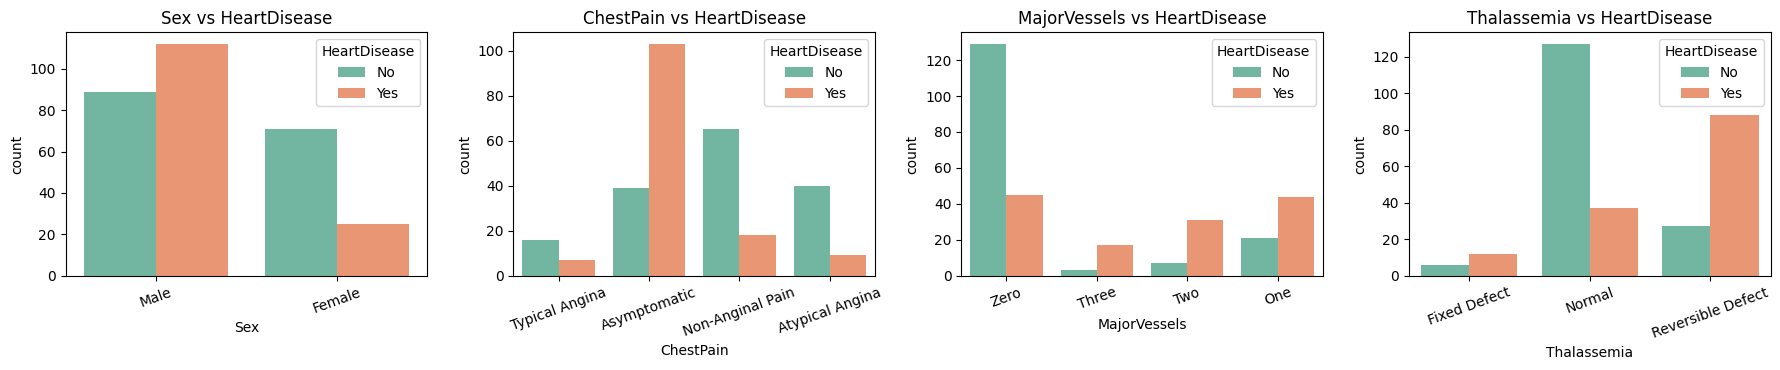

In [5]:
# Quick visual understanding of the pre-processed data
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, col in zip(axes, ["Sex", "ChestPain", "MajorVessels", "Thalassemia"]):
    sns.countplot(data=sample_data, x=col, hue="HeartDisease", ax=ax, palette="Set2")
    ax.set_title(f"{col} vs HeartDisease")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

#### Step 3.3: Exploratory Data Analysis (EDA)
How does each of the 4 selected inputs relate to heart disease? (percentage of patients with heart disease in each category)

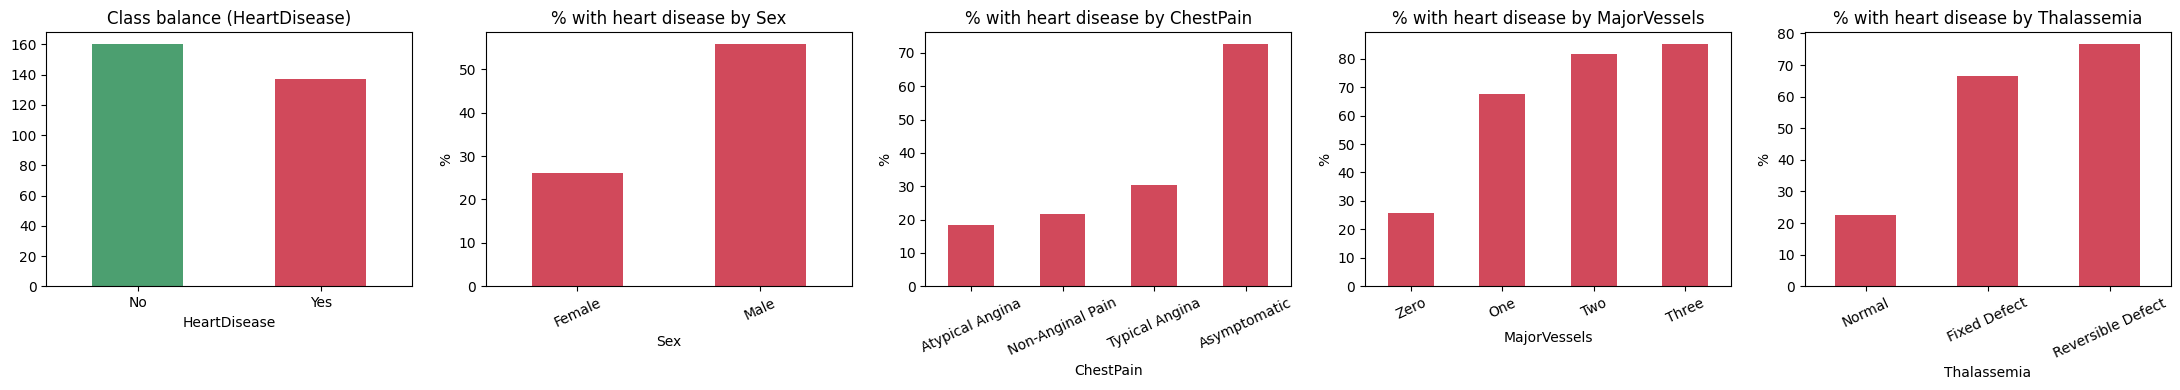


Sex: % with heart disease
HeartDisease    No   Yes
Sex                     
Female        74.0  26.0
Male          44.3  55.7

ChestPain: % with heart disease
HeartDisease        No   Yes
ChestPain                   
Asymptomatic      27.5  72.5
Atypical Angina   81.6  18.4
Non-Anginal Pain  78.3  21.7
Typical Angina    69.6  30.4

MajorVessels: % with heart disease
HeartDisease    No   Yes
MajorVessels            
One           32.3  67.7
Three         15.0  85.0
Two           18.4  81.6
Zero          74.1  25.9

Thalassemia: % with heart disease
HeartDisease         No   Yes
Thalassemia                  
Fixed Defect       33.3  66.7
Normal             77.4  22.6
Reversible Defect  23.5  76.5

Observations:
- Asymptomatic chest pain, 2-3 blocked vessels and a Reversible Defect all show much higher heart-disease rates.
- Males show a higher rate than females in this dataset.
- The classes are reasonably balanced (160 No / 137 Yes), so accuracy is a fair metric.


In [6]:
"""
Purpose: EDA - heart-disease rate per category of each selected input, and class balance.
"""
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

# class balance
sample_data["HeartDisease"].value_counts().plot(kind="bar", ax=axes[0], color=["#4C9F70", "#D1495B"])
axes[0].set_title("Class balance (HeartDisease)"); axes[0].tick_params(axis="x", rotation=0)

# heart-disease rate per category
for ax, col in zip(axes[1:], ["Sex", "ChestPain", "MajorVessels", "Thalassemia"]):
    rate = sample_data.groupby(col)["HeartDisease"].apply(lambda s: (s == "Yes").mean() * 100)
    rate.sort_values().plot(kind="bar", ax=ax, color="#D1495B")
    ax.set_title(f"% with heart disease by {col}"); ax.set_ylabel("%"); ax.tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

for col in ["Sex", "ChestPain", "MajorVessels", "Thalassemia"]:
    print(f"\n{col}: % with heart disease")
    print(pd.crosstab(sample_data[col], sample_data["HeartDisease"], normalize="index").mul(100).round(1))

print("\nObservations:")
print("- Asymptomatic chest pain, 2-3 blocked vessels and a Reversible Defect all show much higher heart-disease rates.")
print("- Males show a higher rate than females in this dataset.")
print("- The classes are reasonably balanced (160 No / 137 Yes), so accuracy is a fair metric.")

#### Step 4: Feature Extraction
o   Features are already extracted (the 4 selected attributes)  
o   No further Feature Extraction needs to be performed

### Step 5: Label Encoding the Sample Data (Input and Output converted to Numeric Representation)
#### Step 5.1: Train the Label Encoder

In [7]:
"""
Purpose: train one LabelEncoder per attribute on its fixed list of possible values.
"""
sex = pd.DataFrame({"Sex": ["Female", "Male"]})
chest_pain = pd.DataFrame({"ChestPain": ["Typical Angina", "Atypical Angina", "Non-Anginal Pain", "Asymptomatic"]})
major_vessels = pd.DataFrame({"MajorVessels": ["Zero", "One", "Two", "Three"]})
thalassemia = pd.DataFrame({"Thalassemia": ["Normal", "Fixed Defect", "Reversible Defect"]})
heart_disease = pd.DataFrame({"HeartDisease": ["Yes", "No"]})

sex_label_encoder = LabelEncoder()
chest_pain_label_encoder = LabelEncoder()
major_vessels_label_encoder = LabelEncoder()
thalassemia_label_encoder = LabelEncoder()
heart_disease_label_encoder = LabelEncoder()

sex_label_encoder.fit(np.ravel(sex))
chest_pain_label_encoder.fit(np.ravel(chest_pain))
major_vessels_label_encoder.fit(np.ravel(major_vessels))
thalassemia_label_encoder.fit(np.ravel(thalassemia))
heart_disease_label_encoder.fit(np.ravel(heart_disease))

for name, enc in [("Sex", sex_label_encoder), ("ChestPain", chest_pain_label_encoder),
                  ("MajorVessels", major_vessels_label_encoder),
                  ("Thalassemia", thalassemia_label_encoder),
                  ("HeartDisease", heart_disease_label_encoder)]:
    print(f"{name:15s}", dict(zip(enc.classes_, enc.transform(enc.classes_))))

Sex             {'Female': np.int64(0), 'Male': np.int64(1)}
ChestPain       {'Asymptomatic': np.int64(0), 'Atypical Angina': np.int64(1), 'Non-Anginal Pain': np.int64(2), 'Typical Angina': np.int64(3)}
MajorVessels    {'One': np.int64(0), 'Three': np.int64(1), 'Two': np.int64(2), 'Zero': np.int64(3)}
Thalassemia     {'Fixed Defect': np.int64(0), 'Normal': np.int64(1), 'Reversible Defect': np.int64(2)}
HeartDisease    {'No': np.int64(0), 'Yes': np.int64(1)}


#### Step 5.2: Label Encode the Output

In [8]:
"""
Purpose: encode the output attribute (HeartDisease: No/Yes -> 0/1).
"""
sample_data = sample_data.copy()
sample_data_encoded_output = sample_data.copy()

print("\n\nHeartDisease Attribute After Label Encoding:")
print("============================================\n")
sample_data["encoded_heart_disease"] = heart_disease_label_encoder.transform(sample_data["HeartDisease"])
print(sample_data[["HeartDisease", "encoded_heart_disease"]].head(10))

sample_data_encoded_output[["Sex", "ChestPain", "MajorVessels", "Thalassemia", "HeartDisease"]] = \
    sample_data[["Sex", "ChestPain", "MajorVessels", "Thalassemia", "encoded_heart_disease"]]
sample_data_encoded_output.to_csv("sample-data-encoded-output.csv", index=False, header=True)
print("\nSaved: sample-data-encoded-output.csv")



HeartDisease Attribute After Label Encoding:

  HeartDisease  encoded_heart_disease
0           No                      0
1          Yes                      1
2          Yes                      1
3           No                      0
4           No                      0
5           No                      0
6          Yes                      1
7           No                      0
8          Yes                      1
9          Yes                      1

Saved: sample-data-encoded-output.csv


#### Step 5.3: Label Encode the Input

In [9]:
"""
Purpose: encode the 4 input attributes into numeric values.
"""
sample_data_encoded = sample_data_encoded_output.copy()

sample_data_encoded_output["encoded_sex"] = sex_label_encoder.transform(sample_data_encoded_output["Sex"])
sample_data_encoded_output["encoded_chest_pain"] = chest_pain_label_encoder.transform(sample_data_encoded_output["ChestPain"])
sample_data_encoded_output["encoded_major_vessels"] = major_vessels_label_encoder.transform(sample_data_encoded_output["MajorVessels"])
sample_data_encoded_output["encoded_thalassemia"] = thalassemia_label_encoder.transform(sample_data_encoded_output["Thalassemia"])

sample_data_encoded[["Sex", "ChestPain", "MajorVessels", "Thalassemia", "HeartDisease"]] = \
    sample_data_encoded_output[["encoded_sex", "encoded_chest_pain", "encoded_major_vessels",
                                "encoded_thalassemia", "HeartDisease"]]

print("\n\nSample Data after Label Encoding:")
print("=================================\n")
print(sample_data_encoded.head(10))
sample_data_encoded.to_csv("sample-data-encoded.csv", index=False, header=True)



Sample Data after Label Encoding:

   Sex  ChestPain  MajorVessels  Thalassemia  HeartDisease
0    1          3             3            0             0
1    1          0             1            1             1
2    1          0             2            2             1
3    1          2             3            1             0
4    0          1             3            1             0
5    1          1             3            1             0
6    0          0             2            1             1
7    0          0             3            1             0
8    1          0             0            2             1
9    1          0             3            2             1


### Step 6: Execute the Training Phase
#### Step 6.1: Splitting Sample Data into Training Data and Testing Data

In [10]:
"""
Purpose: split into 80% training and 20% testing data.
stratify keeps the Yes/No proportion the same in both parts; random_state makes it reproducible.
"""
training_data_encoded, testing_data_encoded = train_test_split(
    sample_data_encoded, test_size=0.2, random_state=0, shuffle=True,
    stratify=sample_data_encoded["HeartDisease"])

training_data_encoded.to_csv("training-data-encoded.csv", index=False, header=True)
testing_data_encoded.to_csv("testing-data-encoded.csv", index=False, header=True)

print("Training Data shape:", training_data_encoded.shape)
print("Testing Data shape:", testing_data_encoded.shape)

Training Data shape: (237, 5)
Testing Data shape: (60, 5)


### Step 6.2: Splitting Input Vectors and Outputs / Labels of Training Data

In [11]:
input_vector_train = training_data_encoded.iloc[:, :-1]
output_label_train = training_data_encoded.iloc[:, -1]
print("Input vectors (train) shape:", input_vector_train.shape)
print("Output labels (train) shape:", output_label_train.shape)

Input vectors (train) shape: (237, 4)
Output labels (train) shape: (237,)


### 6.3: Train the Support Vector Classifier

In [12]:
print("\n\nTraining the Support Vector Classifier on Training Data")
print("========================================================\n")
svc_model = svm.SVC(gamma="auto", random_state=0)
svc_model.fit(input_vector_train, np.ravel(output_label_train))
print(svc_model)



Training the Support Vector Classifier on Training Data

SVC(gamma='auto', random_state=0)


### Step 6.4: Save the Trained Model

In [13]:
pickle.dump(svc_model, open("heart_svc_trained_model.pkl", "wb"))
print("Saved: heart_svc_trained_model.pkl")

Saved: heart_svc_trained_model.pkl


### Step 7: Execute the Testing Phase
#### Step 7.1: Splitting Input Vectors and Outputs/Labels of Testing Data

In [14]:
input_vector_test = testing_data_encoded.iloc[:, :-1]
output_label_test = testing_data_encoded.iloc[:, -1]
print("Input vectors (test) shape:", input_vector_test.shape)
print("Output labels (test) shape:", output_label_test.shape)

Input vectors (test) shape: (60, 4)
Output labels (test) shape: (60,)


### Step 7.2: Load the Saved Model

In [15]:
model = pickle.load(open("heart_svc_trained_model.pkl", "rb"))
print("Model loaded from heart_svc_trained_model.pkl")

Model loaded from heart_svc_trained_model.pkl


### Step 7.3: Evaluate the Machine Learning Model
#### Step 7.3.1: Make Predictions with the Trained Model on Testing Data

In [16]:
model_predictions = model.predict(input_vector_test)

pd.options.mode.chained_assignment = None
testing_data_encoded["Predictions"] = model_predictions
testing_data_encoded.to_csv("model-predictions.csv", index=False, header=True)

model_predictions = testing_data_encoded
print("\n\nPredictions Returned by heart_svc_trained_model:")
print("================================================\n")
print(model_predictions.head(15))



Predictions Returned by heart_svc_trained_model:

     Sex  ChestPain  MajorVessels  Thalassemia  HeartDisease  Predictions
69     1          2             3            1             1            0
2      1          0             2            2             1            1
94     1          0             0            2             1            1
119    1          0             2            2             1            1
266    1          0             0            2             1            1
264    1          0             3            2             1            1
281    1          0             1            0             1            1
36     1          0             3            2             1            1
282    0          0             2            0             1            1
192    1          0             2            1             1            1
271    1          3             3            2             0            0
230    0          1             0            1             0

### Step 7.4: Calculate the Accuracy Score

In [17]:
model_accuracy_score = accuracy_score(model_predictions["HeartDisease"], model_predictions["Predictions"])
print("\n\nAccuracy Score:")
print("===============\n")
print(round(model_accuracy_score, 2))



Accuracy Score:

0.88


### Step 7.5: Detailed Evaluation Metrics (Precision, Recall, F1, Confusion Matrix)


Classification Report:

                      precision    recall  f1-score   support

No Heart Disease (0)       0.88      0.91      0.89        32
   Heart Disease (1)       0.89      0.86      0.87        28

            accuracy                           0.88        60
           macro avg       0.88      0.88      0.88        60
        weighted avg       0.88      0.88      0.88        60


Confusion Matrix:

             Predicted: No  Predicted: Yes
Actual: No              29               3
Actual: Yes              4              24


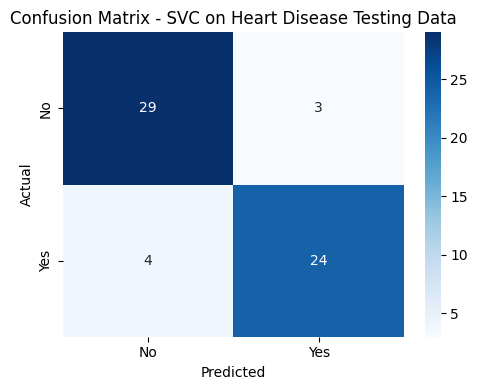

In [18]:
print("\nClassification Report:")
print("=======================\n")
print(classification_report(model_predictions["HeartDisease"], model_predictions["Predictions"],
                            target_names=["No Heart Disease (0)", "Heart Disease (1)"]))

conf_matrix = confusion_matrix(model_predictions["HeartDisease"], model_predictions["Predictions"])
conf_matrix_df = pd.DataFrame(conf_matrix,
    index=["Actual: No", "Actual: Yes"], columns=["Predicted: No", "Predicted: Yes"])
print("\nConfusion Matrix:")
print("==================\n")
print(conf_matrix_df)

plt.figure(figsize=(5, 4))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No", "Yes"], yticklabels=["No", "Yes"])
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.title("Confusion Matrix - SVC on Heart Disease Testing Data")
plt.tight_layout(); plt.show()

### Step 8: Execute the Application Phase
#### Step 8.1: Take Input from User

In [19]:
"""
Purpose: take the 4 inputs from the user. A demo patient is pre-filled so the notebook
runs top-to-bottom; swap in the input() lines to try your own values interactively:

    sex_input = input("Sex (Female, Male): ").strip()
    chest_pain_input = input("ChestPain (Typical Angina, Atypical Angina, Non-Anginal Pain, Asymptomatic): ").strip()
    major_vessels_input = input("MajorVessels (Zero, One, Two, Three): ").strip()
    thalassemia_input = input("Thalassemia (Normal, Fixed Defect, Reversible Defect): ").strip()
"""
sex_input = "Male"
chest_pain_input = "Asymptomatic"
major_vessels_input = "Two"
thalassemia_input = "Reversible Defect"

print(f"Sex: {sex_input}, ChestPain: {chest_pain_input}, MajorVessels: {major_vessels_input}, Thalassemia: {thalassemia_input}")

Sex: Male, ChestPain: Asymptomatic, MajorVessels: Two, Thalassemia: Reversible Defect

### Step 8.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [20]:
user_input = pd.DataFrame({
    "Sex": [sex_input],
    "ChestPain": [chest_pain_input],
    "MajorVessels": [major_vessels_input],
    "Thalassemia": [thalassemia_input],
})
print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:



    Sex     ChestPain MajorVessels        Thalassemia
0  Male  Asymptomatic          Two  Reversible Defect


### Step 8.3: Label Encoding of Feature Vector (Exactly Same as Label Encoded Feature Vectors of Sample Data)

In [21]:
unseen_data_features = user_input.copy()
unseen_data_features["Sex"] = sex_label_encoder.transform(user_input["Sex"])
unseen_data_features["ChestPain"] = chest_pain_label_encoder.transform(user_input["ChestPain"])
unseen_data_features["MajorVessels"] = major_vessels_label_encoder.transform(user_input["MajorVessels"])
unseen_data_features["Thalassemia"] = thalassemia_label_encoder.transform(user_input["Thalassemia"])
print("\n\nUser Input Encoded Feature Vector:")
print("==================================\n")
print(unseen_data_features)



User Input Encoded Feature Vector:

   Sex  ChestPain  MajorVessels  Thalassemia
0    1          0             2            2


### Step 8.4: Load the Saved Model

In [22]:
model = pickle.load(open("heart_svc_trained_model.pkl", "rb"))

### Step 8.5: Model Prediction
#### Step 8.5.1: Apply Model on the Label Encoded Feature Vector of unseen instance and return Prediction to the User

In [23]:
predicted = model.predict(unseen_data_features)

prediction = "HEART DISEASE LIKELY" if predicted[0] == 1 else "NO HEART DISEASE"

pretty_table = PrettyTable()
pretty_table.add_column("       ** Prediction **       ", [prediction])
print(pretty_table)

+--------------------------------+
|        ** Prediction **        |
+--------------------------------+
|      HEART DISEASE LIKELY      |
+--------------------------------+


### Step 9: Execute the Feedback Phase
#### Step 9.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [24]:
example_feedback = pd.DataFrame({
    "Reviewer": ["Domain Expert (Cardiology)", "Domain Expert (Cardiology)", "Student Tester"],
    "Case": [
        "Male, Asymptomatic chest pain, Two major vessels, Reversible Defect -> HEART DISEASE LIKELY",
        "Female, Atypical Angina, Zero major vessels, Normal thallium result -> NO HEART DISEASE",
        "Female, Typical Angina, Zero major vessels, Fixed Defect -> NO HEART DISEASE (unexpected)",
    ],
    "Feedback": [
        "Consistent with clinical expectation: blocked vessels plus a reversible perfusion defect is a high-risk pattern.",
        "Consistent with clinical expectation: low-risk profile.",
        "A fixed defect can indicate past damage; the model may be under-weighting it because only 4 inputs are used. Needs more attributes.",
    ],
})
print(example_feedback.to_string(index=False))

                  Reviewer                                                                                        Case                                                                                                                            Feedback
Domain Expert (Cardiology) Male, Asymptomatic chest pain, Two major vessels, Reversible Defect -> HEART DISEASE LIKELY                    Consistent with clinical expectation: blocked vessels plus a reversible perfusion defect is a high-risk pattern.
Domain Expert (Cardiology)     Female, Atypical Angina, Zero major vessels, Normal thallium result -> NO HEART DISEASE                                                                             Consistent with clinical expectation: low-risk profile.
            Student Tester   Female, Typical Angina, Zero major vessels, Fixed Defect -> NO HEART DISEASE (unexpected) A fixed defect can indicate past damage; the model may be under-weighting it because only 4 inputs are used. Needs more attribut

#### Step 9.2: Make a List of Potential Improvements

In [25]:
improvements = [
    "Add more clinical attributes (age, resting blood pressure, cholesterol, exercise angina, max heart rate) - the assignment limits this version to 4 inputs",
    "Use numeric attributes directly (e.g. age, heart rate) instead of category labels to avoid losing information, and use one-hot encoding for unordered categories such as chest-pain type",
    "Merge the other three UCI centres (Hungary, Switzerland, Long Beach) for more training data",
    "Use cross-validation and compare other models (Logistic Regression, Random Forest, Gradient Boosting)",
    "Tune the decision threshold - for medical screening, missing a sick patient (false negative) is costlier than a false alarm",
]
for i, item in enumerate(improvements, 1):
    print(f"{i}. {item}")

1. Add more clinical attributes (age, resting blood pressure, cholesterol, exercise angina, max heart rate) - the assignment limits this version to 4 inputs
2. Use numeric attributes directly (e.g. age, heart rate) instead of category labels to avoid losing information, and use one-hot encoding for unordered categories such as chest-pain type
3. Merge the other three UCI centres (Hungary, Switzerland, Long Beach) for more training data
4. Use cross-validation and compare other models (Logistic Regression, Random Forest, Gradient Boosting)
5. Tune the decision threshold - for medical screening, missing a sick patient (false negative) is costlier than a false alarm


#### Step 9.3: Improve the Model Based on Feedback

In [26]:
print("Next version: add more attributes, evaluate with cross-validation, "
      "then replace heart_svc_trained_model.pkl only if recall for 'Yes' improves.")

Next version: add more attributes, evaluate with cross-validation, then replace heart_svc_trained_model.pkl only if recall for 'Yes' improves.


## Step 10: Deploy Your Model to the Cloud (Streamlit Community Cloud)

The trained model is deployed as a public web app. Files needed (all included): `app.py`, `heart_svc_trained_model.pkl`, `requirements.txt`, `runtime.txt`.

1. Create a **public** GitHub repository (e.g. `heart-disease-predictor`) and upload `app.py`, `heart_svc_trained_model.pkl`, `requirements.txt`, `runtime.txt` to the repository root.
2. Go to **https://share.streamlit.io** and sign in with GitHub.
3. Click **Create app → Deploy a public app from GitHub**, choose your repo, branch `main`, main file `app.py`, then **Deploy**.
4. If the build fails with a package error, open **Settings → General → Python version** and choose **3.11**.
5. Copy the live `https://<something>.streamlit.app` link and paste it at the **very top of this notebook** (first cell).

## Conclusion
Using only 4 input attributes (Sex, Chest Pain type, number of Major Vessels and the Thalassemia test result) from the UCI Cleveland Heart Disease data, a Support Vector Classifier was trained following the same end-to-end ML cycle as the Titanic system: data understanding, pre-processing, label encoding, training, testing, application and feedback phases, followed by cloud deployment. The accuracy and classification report in Step 7 summarise performance on the held-out 20% test set. The model is for learning purposes only and must not be used for real medical decisions.